In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

This file uses the data of `../Fig-threshold-crossings`.

The threshold is fitted with the finite-size scaling ansatz of https://thesis.caltech.edu/1747/01/jimh_thesis.pdf Sec. 4.5.2, $p_{\rm log} = A + Bx + Cx^2 + D d^{-1/\mu}$ with $x = (p - p_{\rm th}) d^{1/\nu}$, each point weighted by its binomial standard deviation. The statistical error of $p_{\rm th}$ comes from the covariance of the fit, scaled by $\sqrt{\chi^2/{\rm dof}}$ when the ansatz does not describe the data within their errors. The systematic error is half the range of $p_{\rm th}$ over fits in other windows, with each edge of the fit window moved by up to $\pm 0.001$ (two grid points, the upper edge not beyond the data) and the distances fixed. $p_{\rm th}$ changes smoothly with the window, mostly with its lower edge, so half the range is how far it moves within these windows.

The fitted thresholds are written to `fitted_thresholds.csv`, which the crossing plot of `../Fig-threshold-crossings` shows as lines.

In [2]:
# import data from csv file, generated in ../Fig-threshold-crossings
DATA_DIR = Path("../Fig-threshold-crossings/data")

data_ISM    = pd.read_csv(DATA_DIR / "ism.csv")
data_ISM_PP = pd.read_csv(DATA_DIR / "ism_pp.csv")

data_GSM    = pd.read_csv(DATA_DIR / "gsm.csv")
data_GSM_PP = pd.read_csv(DATA_DIR / "gsm_pp.csv")

In [3]:
def sub_data(df, p_min=None, p_max=None, distances=None):
    sub = df.copy()
    if p_min:
        sub = sub[sub["p_phys"] >= p_min - 1e-9]  # tolerance for the np.arange grids of p_phys
    if p_max:
        sub = sub[sub["p_phys"] <= p_max + 1e-9]
    if distances:
        sub = sub[sub["distance"].isin(distances)]
    return sub

In [4]:
# Harrington finite-size scaling model:
def model(theta, p, d):
    p_th, nu, mu, A, B, C, D = theta
    x = (p - p_th) * d**(1 / nu)
    return A + B*x + C*x**2 + D*d**(-1 / mu)


def fit_threshold(df, p_min, p_max, verbose=True):
    """
    Least-squares fit of the model, each point weighted by its binomial standard deviation, with p_th
    bounded to [p_min, p_max]. Returns the parameters, the one-sigma statistical error of p_th and
    chi^2/dof. The error comes from the covariance of the fit and is scaled by sqrt(chi^2/dof) when
    chi^2/dof > 1, i.e. when the model does not describe the data within their errors.
    """
    d = df["distance"].to_numpy(float)
    p = df["p_phys"].to_numpy(float)
    y = df["p_log"].to_numpy(float)
    sigma = np.sqrt(y * (1 - y) / df["num_shots"].to_numpy(float))

    def residuals(theta):
        return (y - model(theta, p, d)) / sigma

    theta0 = [(p_min + p_max) / 2, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

    fit = least_squares(
        residuals,
        theta0,
        bounds=(
            [p_min, 0.1, 0.1, -np.inf, -np.inf, -np.inf, -np.inf],
            [p_max, 10.0, 10.0, np.inf, np.inf, np.inf, np.inf],
        ),
    )
    chi2_dof = 2 * fit.cost / (len(y) - len(fit.x))
    covariance = np.linalg.pinv(fit.jac.T @ fit.jac)
    p_th_err = np.sqrt(covariance[0, 0]) * max(1.0, np.sqrt(chi2_dof))
    if verbose:
        p_th, nu, mu = fit.x[:3]
        print(f"p_th = {p_th:.5f} +- {p_th_err:.5f} (statistical)")
        print(f"nu   = {nu:.4f}")
        print(f"mu   = {mu:.4f}")
        print(f"chi^2/dof = {chi2_dof:.1f}")
    return fit.x, p_th_err, chi2_dof


def systematic_error(df, distances, p_min, p_max, steps=2, step=0.0005):
    """
    Half the range of p_th over fits in other windows: each edge of the window is moved by up to
    `steps` grid points in either direction, the upper edge not beyond the data. Fits whose p_th ends
    on an edge of its window are left out.
    """
    p_data = df["p_phys"].max()
    p_top = min(p_max, p_data)  # upper edge of the data in the window
    values, at_edge = [], 0
    for lower in p_min + step * np.arange(-steps, steps + 1):
        for upper in p_top + step * np.arange(-steps, steps + 1):
            if upper > p_data + 1e-9:
                continue
            theta, _, _ = fit_threshold(sub_data(df, p_min=lower, p_max=upper, distances=distances), lower, upper,
                                        verbose=False)
            if np.isclose(theta[0], lower, atol=1e-7) or np.isclose(theta[0], upper, atol=1e-7):
                at_edge += 1
                continue
            values.append(theta[0])
    values = np.array(values)
    print(f"window scan: {len(values)} windows (+ {at_edge} with p_th on an edge, left out), "
          f"p_th = {values.min():.5f} - {values.max():.5f}")
    systematic = (values.max() - values.min()) / 2
    print(f"systematic error = {systematic:.5f}")
    return systematic

In [5]:
def plt_style(ax, size, width, length):
    """Font size, thick box and ticks of the figures of the paper."""
    ax.tick_params(axis="both", which="both", labelsize=size)
    for spine in ax.spines.values():
        spine.set_linewidth(width)
    ax.tick_params(axis="both", which="major", width=width, length=length)
    ax.tick_params(axis="both", which="minor", width=width / 2, length=length * 2 / 3)


def plot_fit(df, theta, ax, save_path=None):
    """Fitted data (points) and fit (lines), with the data collapse onto the scaling function as an inset."""
    p_th, nu, mu, A, B, C, D = theta
    for d in sorted(df["distance"].unique()):
        sub = df[df["distance"] == d].sort_values("p_phys")
        points, = ax.plot(sub["p_phys"], sub["p_log"], "o", markersize=12, label=f"d={d}")
        p_fit = np.linspace(sub["p_phys"].min(), sub["p_phys"].max(), 300)
        ax.plot(p_fit, model(theta, p_fit, d), color=points.get_color(), linewidth=3)
    ax.axvline(p_th, color="black", linestyle="dashed", linewidth=2.5, label=rf"$p_{{\rm th}}={p_th:.4f}$")
    ax.set_yscale("log")
    ax.xaxis.set_major_locator(plt.MultipleLocator(0.001))
    ax.legend(loc="upper left", ncol=2, prop={"size": 24})
    ax.set_xlabel("Physical error probability", size=28)
    ax.set_ylabel("Code failure rate", size=28)
    plt_style(ax, size=28, width=3, length=12)

    # inset: data collapse onto the scaling function A + Bx + Cx^2
    inset = ax.inset_axes([0.66, 0.2, 0.3, 0.35])
    for d in sorted(df["distance"].unique()):
        sub = df[df["distance"] == d]
        x = (sub["p_phys"] - p_th) * d**(1 / nu)
        inset.plot(x, sub["p_log"] - D * d**(-1 / mu), "o", markersize=7)
    x = np.linspace(*inset.get_xlim(), 200)
    inset.plot(x, A + B*x + C*x**2, color="black", linewidth=2)
    inset.axvline(0, color="black", linestyle="dashed", linewidth=1.5)
    inset.set_xlabel(r"$(p-p_{\rm th})\,d^{1/\nu}$", size=24)
    inset.set_ylabel(r"$p_{\rm log}-D\,d^{-1/\mu}$", size=24)
    plt_style(inset, size=24, width=2, length=7)
    if save_path is not None:
        ax.figure.savefig(save_path, format="pdf", bbox_inches="tight")
    plt.show()

In [6]:
fitted_thresholds = {}  # decoder: p_th and its errors, written to fitted_thresholds.csv at the end


def analyse(decoder, df, distances, p_min, p_max, save_path=None):
    """Fit, errors and figure of one decoder."""
    df_fit = sub_data(df, p_min=p_min, p_max=p_max, distances=distances)
    theta, p_th_err, _ = fit_threshold(df_fit, p_min, p_max)
    systematic = systematic_error(df, distances, p_min, p_max)
    fitted_thresholds[decoder] = dict(p_th=theta[0], statistical_error=p_th_err, systematic_error=systematic)
    fig, ax = plt.subplots(figsize=(16, 9))
    plot_fit(df_fit, theta, ax, save_path=save_path)

In [7]:
FIT_DISTANCES = [9, 11, 13, 15, 17, 19]

# Fig. a): MWPM+PP

p_th = 0.01657 +- 0.00007 (statistical)
nu   = 0.8493
mu   = 0.7424
chi^2/dof = 3.2
window scan: 15 windows (+ 0 with p_th on an edge, left out), p_th = 0.01626 - 0.01698
systematic error = 0.00036


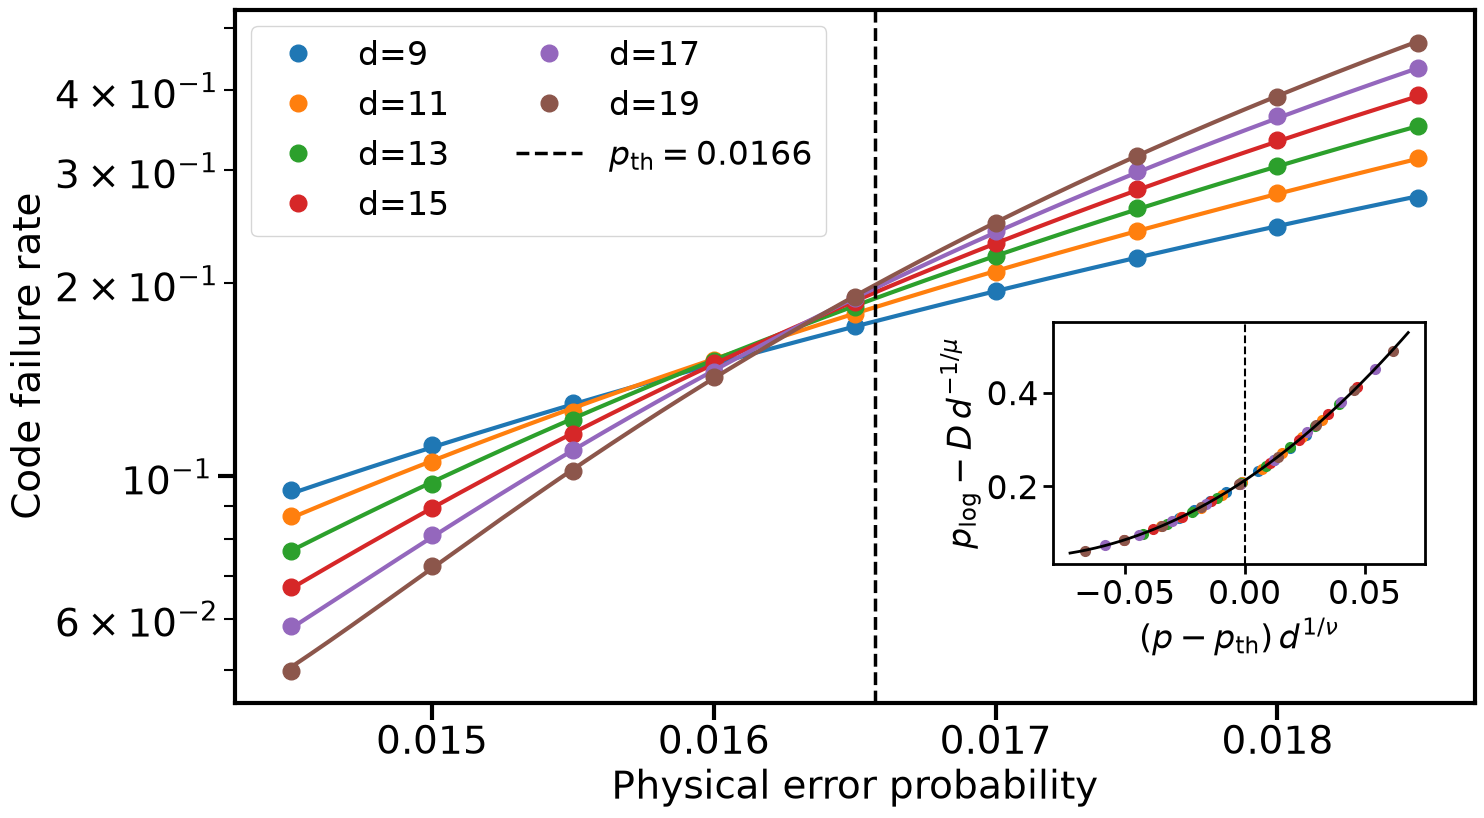

In [8]:
P_MIN = 0.0145
P_MAX = 0.0195

analyse("gsm_pp", data_GSM_PP, FIT_DISTANCES, P_MIN, P_MAX, save_path="./Fig-threshold-fit-a.pdf")

# Fig. b): MWPM

p_th = 0.01616 +- 0.00009 (statistical)
nu   = 0.8412
mu   = 0.7704
chi^2/dof = 6.7
window scan: 15 windows (+ 0 with p_th on an edge, left out), p_th = 0.01581 - 0.01661
systematic error = 0.00040


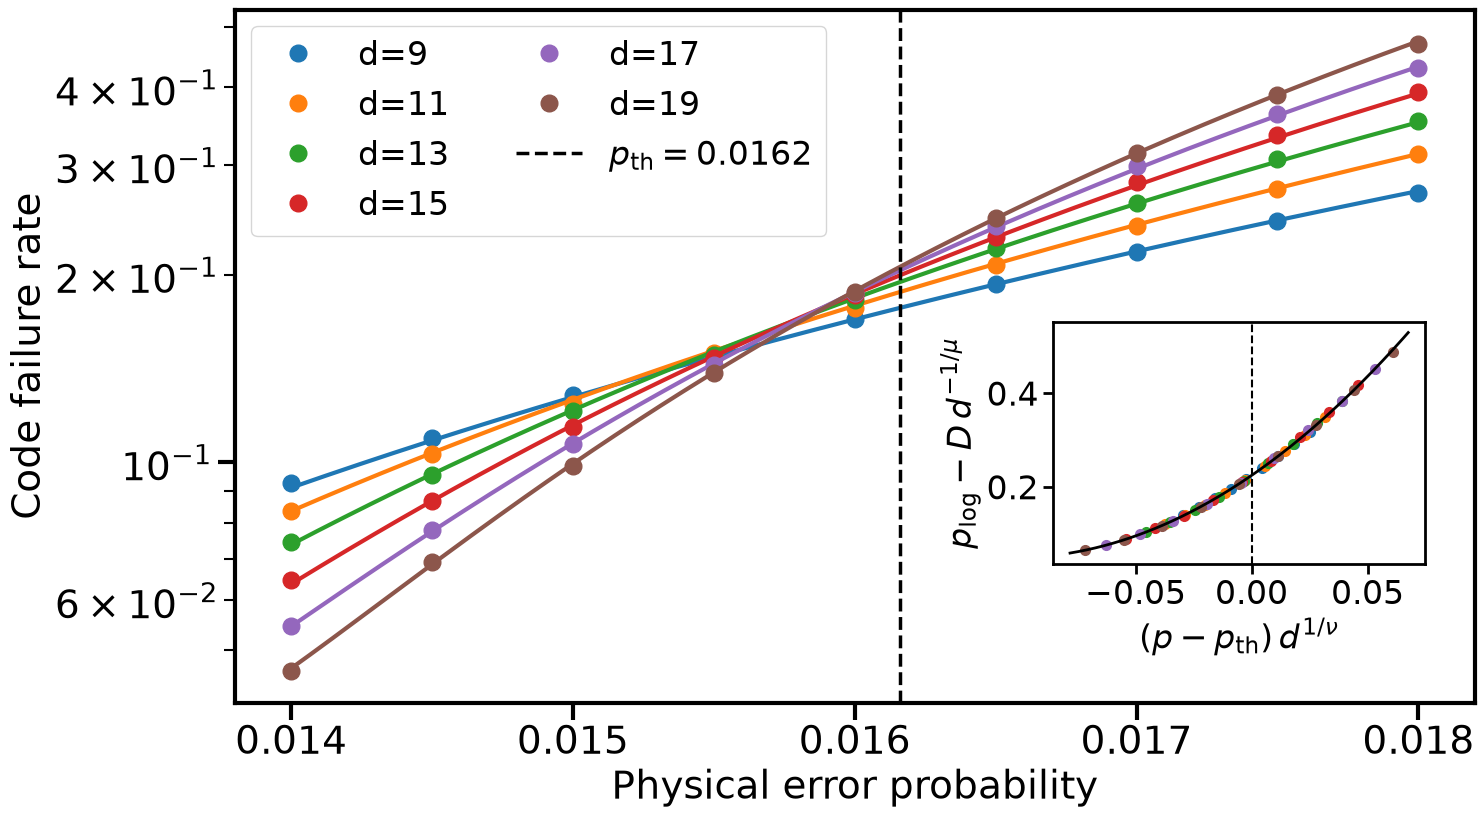

In [9]:
P_MIN = 0.014
P_MAX = 0.018

analyse("gsm", data_GSM, FIT_DISTANCES, P_MIN, P_MAX, save_path="./Fig-threshold-fit-b.pdf")

p_th = 0.01613 +- 0.00012 (statistical)
nu   = 0.8496
mu   = 0.9492
chi^2/dof = 13.3
window scan: 15 windows (+ 0 with p_th on an edge, left out), p_th = 0.01556 - 0.01670
systematic error = 0.00057


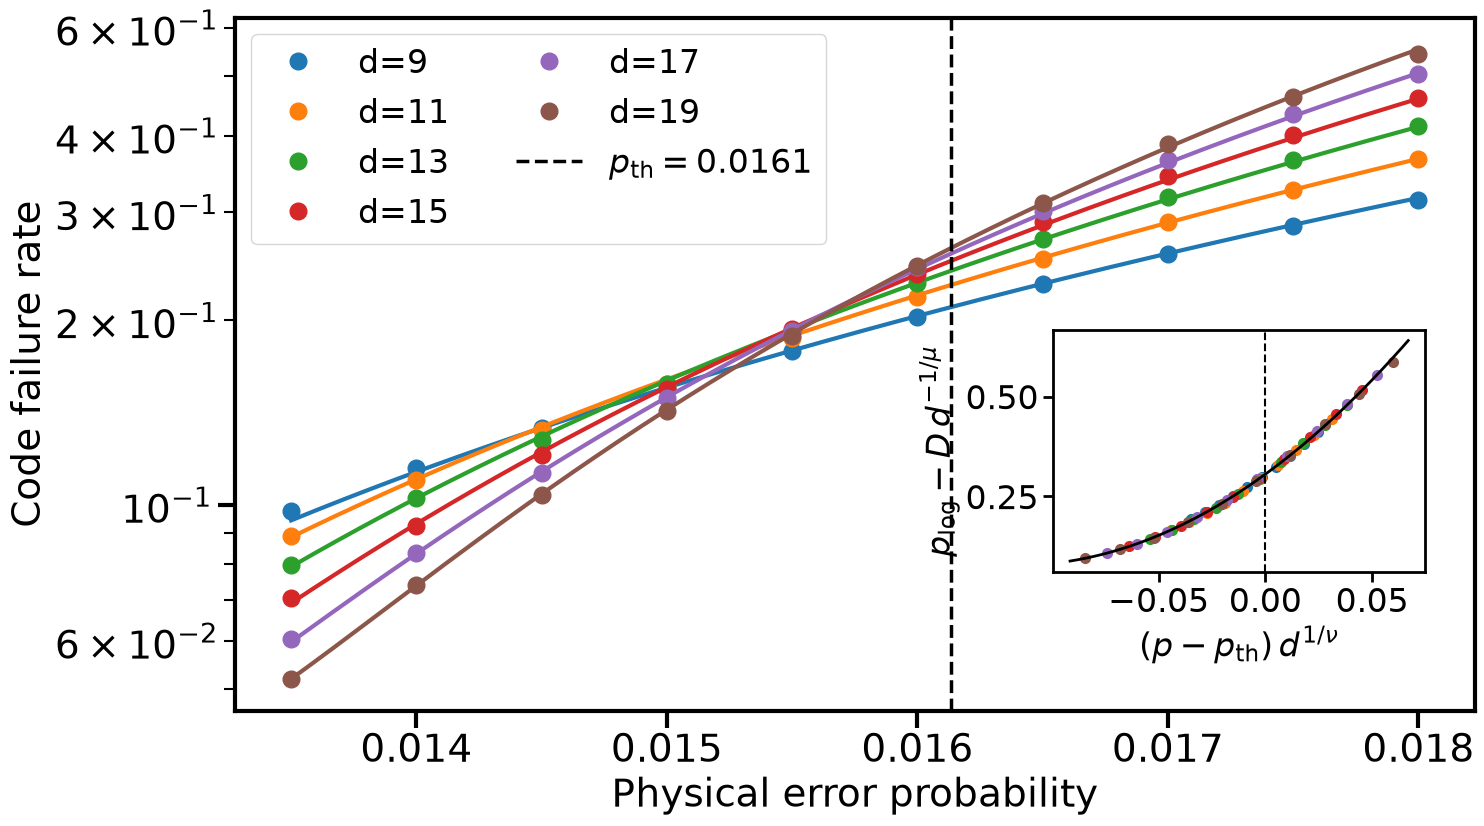

In [10]:
P_MIN = 0.0135
P_MAX = 0.018

analyse("ism_pp", data_ISM_PP, FIT_DISTANCES, P_MIN, P_MAX)

ISM: the fitted threshold follows the upper edge of the window and the model does not describe the data, so no threshold is fitted for ISM.

In [11]:
# P_MIN = 0.011
# P_MAX = 0.0165

# analyse("ism", data_ISM, FIT_DISTANCES, P_MIN, P_MAX)

In [13]:
# fitted thresholds, shown as lines in the crossing plot of ../Fig-threshold-crossings
fitted = pd.DataFrame.from_dict(fitted_thresholds, orient="index").rename_axis("decoder").reset_index()
fitted.to_csv("fitted_thresholds.csv", index=False)
fitted

,decoder,p_th,statistical_error,systematic_error
0,gsm_pp,0.016571,0.000066,0.000357
1,gsm,0.016161,0.000094,0.000398
2,ism_pp,0.016134,0.000122,0.000570
